# 01 Explore the data
What does the Eedi Task 3/4 data look like before we build any model?

In [2]:
import sys
sys.path.append("..")

import pandas as pd
import matplotlib.pyplot as plt
from src.data import load_data

df = load_data()
df.shape

(1382727, 17)

## 1. Dataset at a glance
How big is the data, and what time period does it cover?

In [3]:
print("Answers:  ", f"{len(df):,}")
print("Students: ", f"{df['UserId'].nunique():,}")
print("Questions:", f"{df['QuestionId'].nunique():,}")
print("From", df["DateAnswered"].min().date(), "to", df["DateAnswered"].max().date())

Answers:   1,382,727
Students:  4,918
Questions: 948
From 2019-09-06 to 2020-05-01


**Takeaway:** 1.38 million answers from 4,918 students on 948 questions, over one school year.

## 2. Data quality
Are there duplicates, and can we trust the target?

In [5]:
print("Duplicate answers:", df["AnswerId"].duplicated().sum())
print("Student answered same question twice:", df.duplicated(subset=["UserId", "QuestionId"]).sum())
right_option = df["CorrectAnswer"] == df["AnswerValue"]
print("IsCorrect mismatches:", (right_option != df["IsCorrect"]).sum())

Duplicate answers: 0
Student answered same question twice: 0
IsCorrect mismatches: 0


**Takeaway:** No duplicates, and IsCorrect always matches the student's choice. No student answers the same question twice.

## 3. Target: IsCorrect
How balanced are correct and incorrect answers?

In [7]:
print("Percent correct:", round(df["IsCorrect"].mean() * 100, 1))

Percent correct: 53.7


**Takeaway:** 53.7% of answers are correct. Always guessing "correct" gives 53.7% accuracy, so this is the baseline to beat. The classes are nearly balanced, so accuracy is a fair metric.

## 4. Student confidence
How many answers have a rating, and are students as correct as they think?

In [9]:
print(df["Confidence"].value_counts(dropna=False).sort_index())
print("Rated:", f"{df['Confidence'].notna().mean() * 100:.1f}% of answers")

Confidence
0.0        28733
25.0       17405
50.0       53043
75.0       87778
100.0     159469
NaN      1036299
Name: count, dtype: int64
Rated: 25.1% of answers


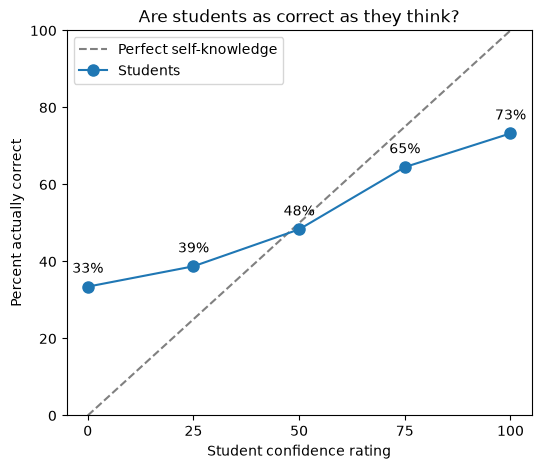

In [10]:
by_conf = df.groupby("Confidence")["IsCorrect"].mean() * 100

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 100], [0, 100], "--", color="gray", label="Perfect self-knowledge")
ax.plot(by_conf.index, by_conf.values, "o-", markersize=8, label="Students")
for conf, pct in by_conf.items():
    ax.annotate(f"{pct:.0f}%", (conf, pct), textcoords="offset points", xytext=(0, 10), ha="center")
ax.set_xlabel("Student confidence rating")
ax.set_ylabel("Percent actually correct")
ax.set_title("Are students as correct as they think?")
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlim(-5, 105)
ax.set_ylim(0, 100)
ax.legend()
plt.show()

**Takeaway:** Only 25% of answers are rated, on 5 levels (0, 25, 50, 75, 100). Answers rated 100 are correct only 73% of the time, so students are overconfident at the top and underconfident at the bottom. But higher ratings always mean more correct answers: the ranking is right, the probabilities are wrong.

About the plot: the gray diagonal is what a student with perfect self-knowledge would look like. The gap between the blue line and the diagonal is our project's motivation

## 5. Student groups
How much group information do we have, and do the groups perform differently?

In [11]:
print("Gender (% of answers; 0 = unspecified, 1 = female, 2 = male, 3 = other):")
print((df["Gender"].value_counts(normalize=True) * 100).round(2))

print("\nFree school meals (% of answers; 1 = eligible, NaN = unknown):")
print((df["PremiumPupil"].value_counts(normalize=True, dropna=False) * 100).round(1))

print("\nPercent correct by free-school-meal status:")
print((df.groupby("PremiumPupil")["IsCorrect"].mean() * 100).round(1))

Gender (% of answers; 0 = unspecified, 1 = female, 2 = male, 3 = other):
Gender
1    34.14
2    33.79
0    32.03
3     0.04
Name: proportion, dtype: float64

Free school meals (% of answers; 1 = eligible, NaN = unknown):
PremiumPupil
NaN    48.8
0.0    36.9
1.0    14.3
Name: proportion, dtype: float64

Percent correct by free-school-meal status:
PremiumPupil
0.0    54.6
1.0    44.4
Name: IsCorrect, dtype: float64


**Takeaway:** 32% of answers have unspecified gender, and "other" is too small (0.04%) to evaluate. Free-school-meal status is unknown for half the answers. Free-school-meal students answer 44.4% correctly vs. 54.6% for others, so we must check whether the models work equally well for both.

## 6. Topics
Which topic level should be the "skill" for our features?

In [16]:
subjects = pd.read_csv("../data/metadata/subject_metadata.csv")
level_of = dict(zip(subjects["SubjectId"], subjects["Level"]))
name_of = dict(zip(subjects["SubjectId"], subjects["Name"]))

q = df.drop_duplicates("QuestionId")

for level in [0, 1, 2, 3]:
    # first topic at this level for each question
    topic = q["SubjectId"].apply(lambda ids: next(i for i in ids if level_of[i] == level))
    per_topic = topic.map(name_of).value_counts()

    print(f"\n=== Level {level}: {len(per_topic)} topics, "
          f"questions per topic from {per_topic.min()} to {per_topic.max()}, "
          f"{(per_topic <= 5).sum()} topics with 5 or fewer")
    print(per_topic.to_string())


=== Level 0: 1 topics, questions per topic from 948 to 948, 0 topics with 5 or fewer
SubjectId
Maths    948

=== Level 1: 3 topics, questions per topic from 144 to 509, 0 topics with 5 or fewer
SubjectId
Number                  509
Geometry and Measure    295
Algebra                 144

=== Level 2: 25 topics, questions per topic from 2 to 141, 1 topics with 5 or fewer
SubjectId
Fractions                                         141
Negative Numbers                                  116
Factors, Multiples and Primes                     106
Basic Arithmetic                                   99
Angles                                             93
Perimeter and Area                                 55
Transformations                                    54
Writing and Simplifying Expressions                44
Co-ordinates                                       35
Fractions, Decimals and Percentage Equivalence     24
Formula                                            22
Symmetry              

**Takeaway:** Every question has one topic at each of 4 levels, from broad to specific.

Level 0 (Maths) is the same for every question, so it adds nothing beyond overall accuracy.

Level 1 has only 3 topics ("Number" alone covers 509 of 948 questions), so on its own it mixes very different skills.

Level 2 has 25 topics and level 3 has 57, but some level-3 topics have only 1 question, so students can never have past history on them.

Broader levels give more history per topic, and narrower levels are more precise. We will choose skill features by forward selection on validation AUC: start with level 2 or 3 (whichever is better alone), then try adding the other levels one at a time, keeping each only if it helps.

## 7. Time order
Timestamps only go to the minute. How often does a student answer several questions in the same minute?

In [15]:
tied = df.duplicated(subset=["UserId", "DateAnswered"], keep=False)
print("Answers in a tie:", f"{tied.sum():,}", f"({tied.mean() * 100:.1f}%)")
df[tied][["UserId", "QuestionId", "QuizId", "DateAnswered", "IsCorrect"]].head(6)

Answers in a tie: 940,464 (68.0%)


,UserId,QuestionId,QuizId,DateAnswered,IsCorrect
1,1,202,75,2019-10-11 13:17:00,0
2,1,420,75,2019-10-11 13:17:00,1
5,1,261,75,2019-10-11 13:20:00,0
6,1,503,75,2019-10-11 13:20:00,0
7,1,289,75,2019-10-11 13:21:00,0
8,1,566,75,2019-10-11 13:21:00,1


**Takeaway:** 68% of answers share a minute with another answer by the same student, usually in the same quiz. We can't know their true order, so features will only count answers from an earlier minute as "the past". This avoids leakage.